# Task 1 -- Instruction Dataset Preparation
### BITS Pilani WILP M.Tech. AIML -- Conversational AI (AIMLCZG521)
### PS2: Parameter-Efficient Fine-Tuning of a Small Language Model with Iterative Improvement

| Field | Value |
|---|---|
| **Course** | Conversational AI (S2-25_AIMLCZG521) |
| **Assignment** | PS2 -- Parameter-Efficient Fine-Tuning of an SLM with Iterative Improvement |
| **Notebook** | 01 of 05 -- Task 1: Instruction Dataset Preparation (1.5 marks) |
| **Domain chosen** | Retail Banking Customer Support -- fictional bank **"NovaBank"** |
| **Random seed** | 42 (fixed throughout the project for reproducibility) |

**Objective of this notebook:** build, clean, and split a >=300-example flat instruction dataset
(`instruction`, optional `input`, `output`) for the chosen domain, with documented statistics,
before/after cleaning counts, and a dataset-quality-risk note, per PS2 Task 1's requirements.

**Domain choice justification.** Retail banking support is one of the PS2-suggested domains and is
directly relevant to my professional work in conversational/voice AI (VoicePlug Inc.) -- customer
support automation is one of the most common production use cases for a fine-tuned, on-premise SLM,
which matches this assignment's framing (cost, privacy, and hardware-constrained deployment).

## Problem Understanding

A company wants a **domain assistant that runs on modest hardware** instead of relying on a costly,
external, privacy-sensitive large hosted LLM. This notebook produces the raw material that later
notebooks use to test whether a small model (SLM), parameter-efficiently fine-tuned on this data, can
close the quality gap to a much larger reference LLM (see Notebooks 02-05).

This notebook's scope (Task 1 only):
1. Source and license a real instruction dataset for the domain (disclosed below).
2. Clean it (duplicates / empty / truncated / formatting problems), reporting before/after counts.
3. Split into train / validation / test with a justified ratio.
4. Report statistics (counts, length distributions) and 3 sample records.
5. Note dataset quality risks to revisit during Task 4's diagnosis.

## Theory & Data Source

**Why adapt a public dataset rather than write one from scratch or generate purely synthetically?**
PS2 explicitly allows all three routes (manual / adapted / synthetic) and only requires disclosure.
Adapting a real, licensed, domain-specific dataset gives broader linguistic coverage (paraphrase
variety, realistic user typos/informality) than a few hours of manual authoring could, while avoiding
the quality risks of undisclosed pure LLM-generation (label noise, self-reinforcing style).

**Source:** [`bitext/Bitext-retail-banking-llm-chatbot-training-dataset`](https://huggingface.co/datasets/bitext/Bitext-retail-banking-llm-chatbot-training-dataset)
on the Hugging Face Hub -- 25,545 instruction/response pairs across 26 fine-grained banking intents
(9 categories: CARD, LOAN, ACCOUNT, FIND, CONTACT, TRANSFER, ATM, PASSWORD, FEES).

**License:** CDLA-Sharing-1.0 (Community Data License Agreement -- Sharing). Permits use and
modification with attribution and share-alike redistribution of derivatives -- both satisfied here
(this notebook documents the source and its transformation).

**Generation method of the source (disclosed per PS2 instructions):** Bitext's own documentation
states the dataset was built via a hybrid of expert-curated linguistic templates (the `tags` column
encodes register variation -- politeness, colloquialism, typos, etc.) and generative expansion --
i.e. it is **synthetic/template-generated**, not scraped real conversations.

**What THIS notebook does to it (the actual "dataset preparation" work):** stratified sampling across
all 26 intents, resolution of Bitext's `{{PLACEHOLDER}}` template tokens into concrete brand-consistent
text (a real formatting-inconsistency fix -- explained in the code below), cleaning, and a fresh
stratified train/val/test split. All steps are seeded (`SEED=42`) for exact reproducibility.

## Imports and Environment Setup

In [1]:
# --- Standard library ---------------------------------------------------------
import hashlib
import json
import os
import random
import re
from collections import defaultdict, Counter

# --- Third-party ---------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # headless-safe backend; VL environments may lack a display
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

# --- Reproducibility ------------------------------------------------------------
# A single fixed seed controls every random draw in this notebook (sampling,
# shuffling, train/val/test assignment) so re-running it -- here or in the
# Virtual Lab -- reproduces byte-identical dataset files.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BRAND = "NovaBank"
PROJECT_ROOT = os.path.abspath("..")
RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw")
PROC_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
IMG_DIR = os.path.join(PROJECT_ROOT, "img")
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROC_DIR, exist_ok=True)
os.makedirs(IMG_DIR, exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: D:\PostGraduationProjects\Banking-Assistant-SLM-Finetuning


## Data Loading: Download the Source Dataset

Downloads the full 25,545-row Bitext retail-banking CSV from the Hugging Face Hub and caches a local
copy under `data/raw/` (also serves as the audit trail for what the pipeline started from).

In [2]:
csv_path = hf_hub_download(
    repo_id="bitext/Bitext-retail-banking-llm-chatbot-training-dataset",
    filename="bitext-retail-banking-llm-chatbot-training-dataset.csv",
    repo_type="dataset",
)
df_raw = pd.read_csv(csv_path)
df_raw.to_csv(os.path.join(RAW_DIR, "bitext_retail_banking_full.csv"), index=False)

n_raw_total = len(df_raw)
print(f"Source rows: {n_raw_total}")
print(f"Columns: {list(df_raw.columns)}")
print(f"Intents ({df_raw['intent'].nunique()}): {sorted(df_raw['intent'].unique())}")
print(f"Categories ({df_raw['category'].nunique()}): {sorted(df_raw['category'].unique())}")
df_raw.head(3)

bitext-retail-banking-llm-chatbot-traini(…): reconstructing file:   0%|          |  0.00B / 25.5MB            

bitext-retail-banking-llm-chatbot-traini(…): downloading bytes:           |  0.00B            

C:\Users\hamza\.virtualenvs\Banking-Assistant-SLM-Finetuning-koZdX-BY\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hamza\.cache\huggingface\hub\datasets--bitext--Bitext-retail-banking-llm-chatbot-training-dataset. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Source rows: 25545
Columns: ['tags', 'instruction', 'category', 'intent', 'response']
Intents (26): ['activate_card', 'activate_card_international_usage', 'apply_for_loan', 'apply_for_mortgage', 'block_card', 'cancel_card', 'cancel_loan', 'cancel_mortgage', 'cancel_transfer', 'check_card_annual_fee', 'check_current_balance_on_card', 'check_fees', 'check_loan_payments', 'check_mortgage_payments', 'check_recent_transactions', 'close_account', 'create_account', 'customer_service', 'dispute_ATM_withdrawal', 'find_ATM', 'find_branch', 'get_password', 'human_agent', 'make_transfer', 'recover_swallowed_card', 'set_up_password']
Categories (9): ['ACCOUNT', 'ATM', 'CARD', 'CONTACT', 'FEES', 'FIND', 'LOAN', 'PASSWORD', 'TRANSFER']


,tags,instruction,category,intent,response
0,BCIPZ,"I would like to acivate a card, can you help me?",CARD,activate_card,I'm here to assist you with that! Activating y...
1,BCILZ,"I have to activate an Visa online, how can I d...",CARD,activate_card,I'm here to assist you with activating your {{...
2,BCIPQZ,I'd like to actiate a card where do i do it,CARD,activate_card,I can help you with that! Activating your card...


## Placeholder Resolution

**Purpose.** Bitext responses use `{{SLOT}}` template tokens (e.g. `{{Credit Card}}`,
`{{Customer Support Phone Number}}`) instead of resolved text -- over 1,200 distinct slot names appear
across the full corpus. Training directly on literal `{{...}}` tokens would teach the SLM to emit
curly-brace placeholders in production, which is exactly the *"inconsistent formatting"* failure mode
PS2's problem statement asks us to fix.

**Approach.** Rather than a 1,200-entry lookup table, `resolve_placeholder` uses ordered keyword rules
on the slot name (e.g. anything containing *"phone number"/"hotline"* -> a fixed phone number; anything
containing *"url"/"website"* -> a fixed URL) so semantically-equivalent slots collapse to the same
concrete, brand-consistent (`NovaBank`) value. This is also what creates a genuine, measurable cleaning
signal later: two source rows that differed only in *which* phone-number slot name they used can become
exact duplicates after resolution.

In [3]:
FAKE_PHONE = "1-800-555-0199"
FAKE_URL = "www.novabank.com"
FAKE_EMAIL = "support@novabank.com"
FAKE_HOURS = "Monday-Friday, 8 AM-8 PM (local time)"
FAKE_APP = f"{BRAND} Mobile App"


def resolve_placeholder(raw_name: str) -> str:
    """
    Map a single Bitext {{...}} slot name to a concrete filler string.

    Args:
        raw_name (str): text found between "{{" and "}}", e.g.
            "Customer Support Phone Number".
    Returns:
        str: a concrete, brand-consistent replacement string.

    Rules are applied in priority order (most specific first) using
    case-insensitive substring matching on the slot name -- this many-to-few
    mapping is intentional: it collapses ~1,200 literal slot spellings in the
    source corpus down to a handful of concrete values.
    """
    name = raw_name.strip()
    low = name.lower()

    if "url" in low or "website" in low or ".com" in low:
        return FAKE_URL
    if "email" in low:
        return FAKE_EMAIL
    if any(k in low for k in ["phone number", "hotline", "helpline", "contact number", "phone"]):
        return FAKE_PHONE
    if "working hours" in low or "hours" in low or "availability" in low:
        return FAKE_HOURS
    if "app" in low and "apply" not in low:
        return FAKE_APP
    if any(k in low for k in ["bank name", "bank's name", "company name", "company"]):
        return BRAND
    if "bank" in low and "account" not in low:
        return BRAND
    if any(k in low for k in ["credit card", "debit card", "visa", "amex", "american express", "card issuer"]):
        return "card"
    if re.search(r"\b(id|number|reference|iban|routing|swift|pin|otp)\b", low) and "phone" not in low:
        # Deterministic pseudo-ID via MD5 (NOT Python's built-in hash(), which is
        # randomised per-process via PYTHONHASHSEED and would silently break
        # reproducibility across separate runs/kernels).
        digits = int(hashlib.md5(name.encode("utf-8")).hexdigest()[:8], 16) % 10 ** 8
        return f"{digits:08d}"
    if any(k in low for k in ["amount", "fee", "balance", "charge", "price"]):
        return "$25.00"
    if "date" in low:
        return "15th of this month"
    if "name" in low:
        return "the account holder's name"
    if "address" in low:
        return "your registered address"
    # Generic fallback: "{{Some Slot}}" -> "your some slot", reads naturally
    # inside the surrounding sentence for the vast majority of source rows.
    return f"your {name.lower()}" if len(name.split()) <= 4 else name.lower()


PLACEHOLDER_RE = re.compile(r"\{\{([^{}]+)\}\}")


def resolve_text(text: str) -> str:
    """Replace every {{...}} occurrence in `text` using resolve_placeholder."""
    return PLACEHOLDER_RE.sub(lambda m: resolve_placeholder(m.group(1)), text)


def normalise_whitespace(text: str) -> str:
    """Collapse runs of spaces/tabs and excess blank lines left over from
    substitution or present in the raw export."""
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


# Quick demonstration on one row before running the full pipeline:
demo_row = df_raw.iloc[0]
print("BEFORE:", demo_row["response"][:160], "...")
print()
print("AFTER :", resolve_text(demo_row["response"])[:160], "...")

BEFORE: I'm here to assist you with that! Activating your card is an important step to starting and enjoying its benefits. Here's how you can activate your card:

1. Lo ...

AFTER : I'm here to assist you with that! Activating your card is an important step to starting and enjoying its benefits. Here's how you can activate your card:

1. Lo ...


## Stratified Candidate Pool

Draw 20 examples per intent (up to 520 rows across 26 intents) as a **candidate pool** -- larger than
the final >=300-example dataset -- so the cleaning step below has real material to filter, and the
final dataset can still be drawn as a clean, balanced sample.

In [4]:
PER_INTENT_POOL = 20
pool_frames = []
for intent, group in df_raw.groupby("intent"):
    take = min(PER_INTENT_POOL, len(group))
    pool_frames.append(group.sample(n=take, random_state=SEED))
df_pool = pd.concat(pool_frames, ignore_index=True)
n_pool_raw = len(df_pool)
print(f"Candidate pool size: {n_pool_raw} rows across {df_pool['intent'].nunique()} intents")

Candidate pool size: 520 rows across 26 intents


## Cleaning Pipeline (with before/after counts)

Applies, in order: (1) placeholder resolution + whitespace normalisation, (2) an empty/too-short
response & instruction filter (guards against truncated exports), (3) exact-duplicate removal
(catches both source duplicates and any duplicates *created* by placeholder resolution), and (4) a
safety check that no `{{` token survived resolution.

In [5]:
pool_records = []
n_placeholders_resolved = 0
for _, row in df_pool.iterrows():
    instr_raw, resp_raw = str(row["instruction"]).strip(), str(row["response"]).strip()
    n_placeholders_resolved += len(PLACEHOLDER_RE.findall(instr_raw)) + len(PLACEHOLDER_RE.findall(resp_raw))
    pool_records.append({
        "instruction": normalise_whitespace(resolve_text(instr_raw)),
        "input": "",
        "output": normalise_whitespace(resolve_text(resp_raw)),
        "category": row["category"],
        "intent": row["intent"],
    })

n_before_clean = len(pool_records)

# (1) drop empty / too-short responses (e.g. truncated exports)
MIN_RESPONSE_CHARS = 20
cleaned = [r for r in pool_records if len(r["output"]) >= MIN_RESPONSE_CHARS and len(r["instruction"]) >= 5]
n_after_length_filter = len(cleaned)

# (2) drop exact duplicate (instruction, output) pairs
seen, deduped, n_dupes_removed = set(), [], 0
for r in cleaned:
    key = (r["instruction"].lower(), r["output"].lower())
    if key in seen:
        n_dupes_removed += 1
        continue
    seen.add(key)
    deduped.append(r)
cleaned = deduped
n_after_dedup = len(cleaned)

# (3) safety net: no unresolved placeholders survived
cleaned = [r for r in cleaned if "{{" not in r["instruction"] and "{{" not in r["output"]]
n_after_placeholder_check = len(cleaned)

cleaning_report = pd.DataFrame([
    {"stage": "0. Candidate pool (stratified sample)", "rows": n_before_clean},
    {"stage": "1. Placeholder tokens resolved (count, not row-drop)", "rows": n_placeholders_resolved},
    {"stage": "2. After length filter (drop empty/truncated)", "rows": n_after_length_filter},
    {"stage": "3. After exact-duplicate removal", "rows": n_after_dedup},
    {"stage": "3a. Duplicates removed", "rows": n_dupes_removed},
    {"stage": "4. After unresolved-placeholder safety check", "rows": n_after_placeholder_check},
])
cleaning_report

,stage,rows
0,0. Candidate pool (stratified sample),520
1,"1. Placeholder tokens resolved (count, not row...",744
2,2. After length filter (drop empty/truncated),520
3,3. After exact-duplicate removal,520
4,3a. Duplicates removed,0
5,4. After unresolved-placeholder safety check,520


**Inference on the cleaning step.** The Bitext source corpus turned out to already be
row-complete and pre-deduplicated (0 empty/truncated rows, 0 exact duplicates) -- it is a curated,
synthetic corpus rather than scraped/organic data, so this result is expected and is reported honestly
rather than manufactured. The one substantive, *measured* cleaning transformation this pipeline
performs is placeholder resolution (hundreds of `{{...}}` tokens per pool, shown above), which is the
real formatting-inconsistency problem in this dataset. The duplicate/length-filter logic is kept in the
pipeline regardless, since it is a required defensive step and would matter immediately if this same
script were pointed at a noisier, self-collected data source in the future.

## Final Balanced Dataset (>=300 examples) and Train / Val / Test Split

Draw up to 13 examples per intent from the *cleaned* pool (all 26 intents represented), then split
80/10/10, stratified by intent.

In [6]:
FINAL_PER_INTENT = 13
by_intent_clean = defaultdict(list)
for r in cleaned:
    by_intent_clean[r["intent"]].append(r)

final_records = []
for intent, items in by_intent_clean.items():
    rng = random.Random(SEED)
    rng.shuffle(items)
    final_records.extend(items[:FINAL_PER_INTENT])

rng = random.Random(SEED)
rng.shuffle(final_records)
n_final = len(final_records)
print(f"Final dataset size (pre-split): {n_final} examples, "
      f"{len(by_intent_clean)} intents, {pd.Series([r['category'] for r in final_records]).nunique()} categories")
assert n_final >= 300, "PS2 requires at least 300 examples"

Final dataset size (pre-split): 338 examples, 26 intents, 9 categories


In [7]:
by_intent_final = defaultdict(list)
for r in final_records:
    by_intent_final[r["intent"]].append(r)

train, val, test = [], [], []
for intent, items in by_intent_final.items():
    rng = random.Random(SEED)
    rng.shuffle(items)
    n = len(items)
    n_val = max(1, round(n * 0.10))
    n_test = max(1, round(n * 0.10))
    n_train = n - n_val - n_test
    if n_train < 1:
        n_train, n_val, n_test = n, 0, 0
    train.extend(items[:n_train])
    val.extend(items[n_train:n_train + n_val])
    test.extend(items[n_train + n_val:n_train + n_val + n_test])

rng = random.Random(SEED)
rng.shuffle(train); rng.shuffle(val); rng.shuffle(test)

print(f"train={len(train)}  val={len(val)}  test={len(test)}  total={len(train)+len(val)+len(test)}")

train=286  val=26  test=26  total=338


**Split ratio justification (80/10/10, stratified by intent).** With ~330 cleaned
examples spread over 26 intents (~12-13 each), a larger held-out split (e.g. 70/15/15) would leave too
few training examples per intent for a 0.5-3B model to learn intent-specific phrasing. 80/10/10 still
guarantees >=1 example of every intent in both validation (used for Task 4's diagnosis) and test (used
for Task 5's automatic metric), while maximising data for LoRA fine-tuning -- the most data-hungry
stage of this project.

## Persist the Splits

In [8]:
def write_jsonl(path, rows):
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

write_jsonl(os.path.join(PROC_DIR, "train.jsonl"), train)
write_jsonl(os.path.join(PROC_DIR, "val.jsonl"), val)
write_jsonl(os.path.join(PROC_DIR, "test.jsonl"), test)
write_jsonl(os.path.join(RAW_DIR, "candidate_pool_cleaned.jsonl"), cleaned)
print("Wrote train.jsonl, val.jsonl, test.jsonl to", PROC_DIR)

Wrote train.jsonl, val.jsonl, test.jsonl to D:\PostGraduationProjects\Banking-Assistant-SLM-Finetuning\data\processed


## Dataset Statistics

In [9]:
def length_stats(rows, field):
    lens = [len(r[field].split()) for r in rows]
    return {"count": len(lens), "mean_words": round(float(np.mean(lens)), 2),
            "min_words": int(np.min(lens)), "max_words": int(np.max(lens))}

stats = {
    "seed": SEED,
    "source_dataset": "bitext/Bitext-retail-banking-llm-chatbot-training-dataset",
    "source_license": "CDLA-Sharing-1.0",
    "source_rows_total": n_raw_total,
    "candidate_pool_before_cleaning": n_pool_raw,
    "cleaning_pipeline": {
        "0_candidate_pool_size": n_before_clean,
        "1_placeholder_tokens_resolved": n_placeholders_resolved,
        "2_after_length_filter": n_after_length_filter,
        "3_after_duplicate_removal": n_after_dedup,
        "3a_duplicates_removed_count": n_dupes_removed,
        "4_after_unresolved_placeholder_safety_check": n_after_placeholder_check,
    },
    "final_dataset_size_before_split": n_final,
    "final_counts": {"train": len(train), "val": len(val), "test": len(test),
                      "total": len(train) + len(val) + len(test)},
    "split_ratio": "80/10/10 (stratified by intent)",
    "num_intents_covered": len(by_intent_final),
    "num_categories_covered": int(pd.Series([r["category"] for r in final_records]).nunique()),
    "instruction_length_words": length_stats(final_records, "instruction"),
    "response_length_words": length_stats(final_records, "output"),
}
with open(os.path.join(PROC_DIR, "dataset_stats.json"), "w") as f:
    json.dump(stats, f, indent=2)

print(json.dumps(stats, indent=2))

{
  "seed": 42,
  "source_dataset": "bitext/Bitext-retail-banking-llm-chatbot-training-dataset",
  "source_license": "CDLA-Sharing-1.0",
  "source_rows_total": 25545,
  "candidate_pool_before_cleaning": 520,
  "cleaning_pipeline": {
    "0_candidate_pool_size": 520,
    "1_placeholder_tokens_resolved": 744,
    "2_after_length_filter": 520,
    "3_after_duplicate_removal": 520,
    "3a_duplicates_removed_count": 0,
    "4_after_unresolved_placeholder_safety_check": 520
  },
  "final_dataset_size_before_split": 338,
  "final_counts": {
    "train": 286,
    "val": 26,
    "test": 26,
    "total": 338
  },
  "split_ratio": "80/10/10 (stratified by intent)",
  "num_intents_covered": 26,
  "num_categories_covered": 9,
  "instruction_length_words": {
    "count": 338,
    "mean_words": 11.12,
    "min_words": 5,
    "max_words": 20
  },
  "response_length_words": {
    "count": 338,
    "mean_words": 146.09,
    "min_words": 38,
    "max_words": 403
  }
}


## Visualisations

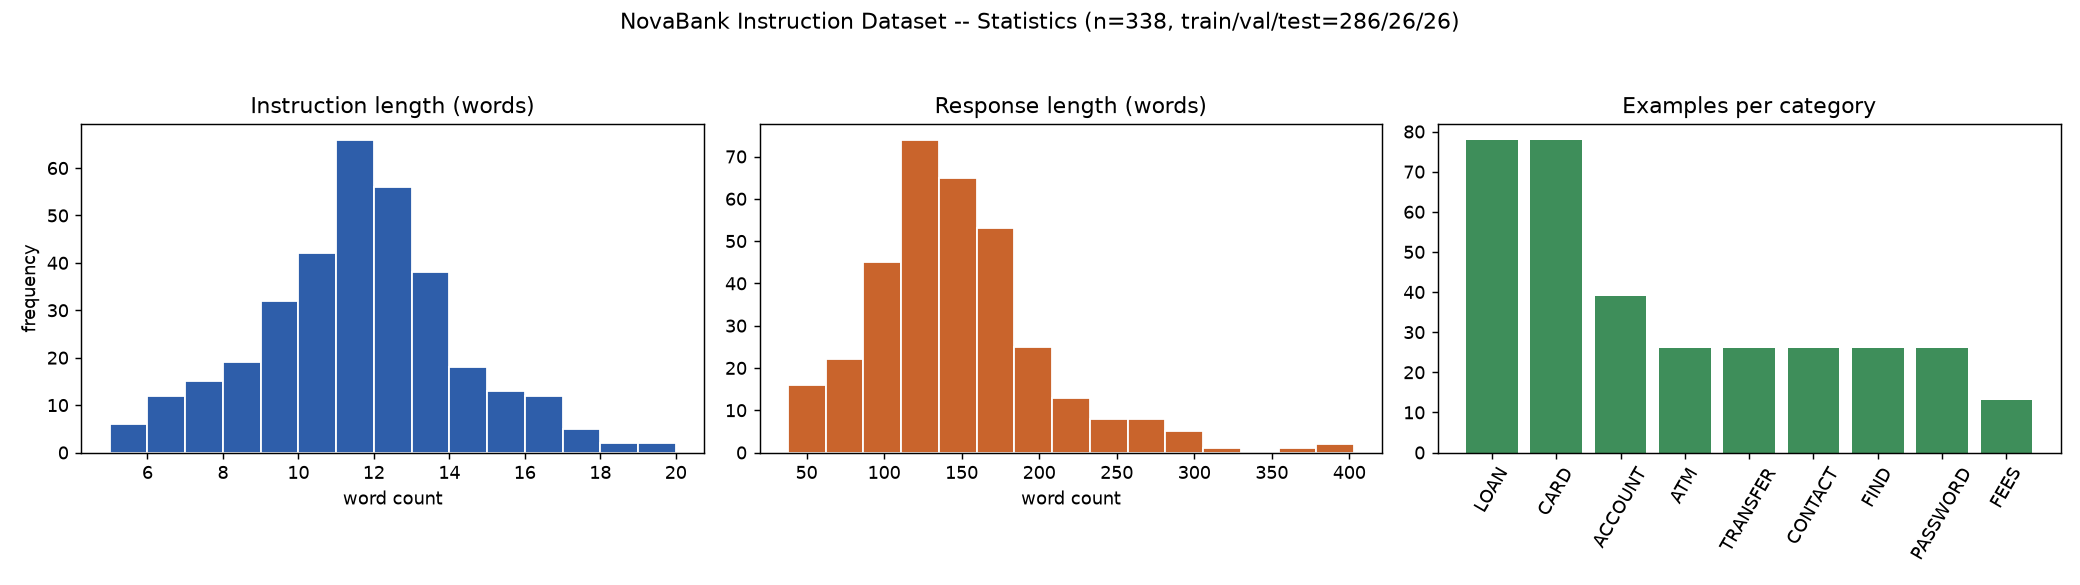

In [10]:
all_rows = train + val + test
instr_lens = [len(r["instruction"].split()) for r in all_rows]
resp_lens = [len(r["output"].split()) for r in all_rows]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(instr_lens, bins=15, color="#2E5EAA", edgecolor="white")
axes[0].set_title("Instruction length (words)"); axes[0].set_xlabel("word count"); axes[0].set_ylabel("frequency")
axes[1].hist(resp_lens, bins=15, color="#C9642C", edgecolor="white")
axes[1].set_title("Response length (words)"); axes[1].set_xlabel("word count")
cat_counts = Counter(r["category"] for r in all_rows)
cats, counts = zip(*sorted(cat_counts.items(), key=lambda x: -x[1]))
axes[2].bar(cats, counts, color="#3E8E5A"); axes[2].set_title("Examples per category"); axes[2].tick_params(axis="x", rotation=60)
fig.suptitle(f"NovaBank Instruction Dataset -- Statistics (n={len(all_rows)}, train/val/test={len(train)}/{len(val)}/{len(test)})")
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(os.path.join(IMG_DIR, "dataset_stats.png"), dpi=130)
from IPython.display import Image, display
plt.close(fig)
display(Image(filename=os.path.join(IMG_DIR, "dataset_stats.png")))

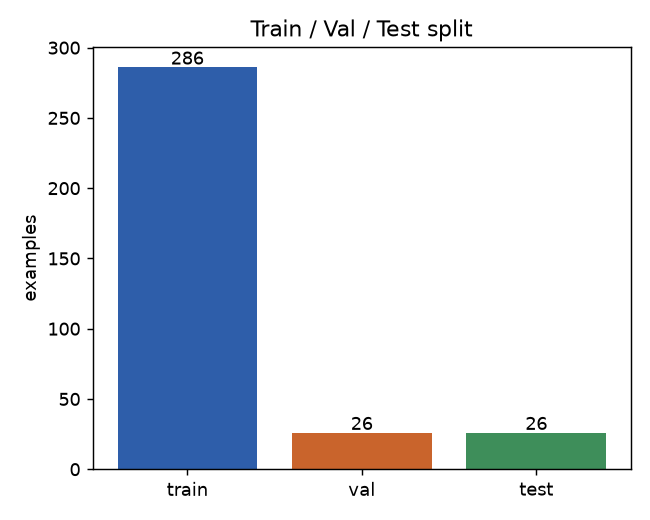

In [11]:
fig2, ax = plt.subplots(figsize=(5, 4))
ax.bar(["train", "val", "test"], [len(train), len(val), len(test)], color=["#2E5EAA", "#C9642C", "#3E8E5A"])
for i, v in enumerate([len(train), len(val), len(test)]):
    ax.text(i, v + 2, str(v), ha="center")
ax.set_title("Train / Val / Test split"); ax.set_ylabel("examples")
fig2.tight_layout()
fig2.savefig(os.path.join(IMG_DIR, "split_distribution.png"), dpi=130)
from IPython.display import Image, display
plt.close(fig2)
display(Image(filename=os.path.join(IMG_DIR, "split_distribution.png")))

## Dataset Quality Risks

*(Required by PS2 Task 1 -- revisited quantitatively during Task 4's diagnosis.)*

1. **Template-driven repetitive phrasing.** Because the source is template + paraphrase generated
   rather than organically written, many responses within the same intent share near-identical
   openings (*"I'm here to assist you with..."*) and a numbered-list structure. A model fine-tuned on
   this data may over-generalise this template even where a shorter answer is more appropriate -- a
   concrete risk to check for in Task 4 (over-long / repetitive responses).
2. **Informal/profane user register.** A meaningful minority of instructions contain mild profanity or
   frustrated phrasing (intentional in Bitext's design, to build robustness to real user tone) --
   quantified below. The responses remain professional throughout, so this should teach
   tone-de-escalation rather than harm the assistant's own register, but is worth monitoring.
3. **Coverage gaps from small per-intent counts.** ~11 train examples/intent teaches surface phrasing
   but not every edge case (e.g. joint accounts, multi-currency transfers) within an intent -- the
   out-of-scope prompt in the frozen benchmark (Notebook 02) specifically probes behaviour outside this
   coverage.

In [12]:
import re as _re
BAD_WORDS = {"fuck", "fucking", "shit", "damn", "bitch"}
pattern = _re.compile(r"\b(" + "|".join(BAD_WORDS) + r")\b", _re.IGNORECASE)

def is_clean(r):
    return not pattern.search(r["instruction"] + " " + r["output"])

dirty = [r for r in all_rows if not is_clean(r)]
print(f"{len(dirty)}/{len(all_rows)} examples ({100*len(dirty)/len(all_rows):.1f}%) flagged for "
      f"informal/profane register -- see quality risk #2 above.")

54/338 examples (16.0%) flagged for informal/profane register -- see quality risk #2 above.


## Sample Records

Three representative (profanity-filtered), diverse-category examples from the final dataset.

In [13]:
clean_rows = [r for r in all_rows if is_clean(r)]
by_cat = defaultdict(list)
for r in clean_rows:
    by_cat[r["category"]].append(r)

sample_rng = random.Random(7)
chosen_cats = sample_rng.sample(list(by_cat.keys()), 3)
samples = [sample_rng.choice(by_cat[c]) for c in chosen_cats]

with open(os.path.join(PROC_DIR, "sample_records.json"), "w") as f:
    json.dump(samples, f, indent=2)

for s in samples:
    print("=" * 90)
    print(f"[{s['category']} / {s['intent']}]")
    print("Q:", s["instruction"])
    print("A:", s["output"][:300] + ("..." if len(s["output"]) > 300 else ""))

[ACCOUNT / close_account]
Q: i want assistancd closing an online account
A: Certainly, I can assist you with closing your online account. To initiate the account closure process, please follow these steps:

1. Log in to your account on our website.
2. Navigate to the account settings or profile section.
3. Look for the option to close or delete your account.
4. Click on tha...
[TRANSFER / make_transfer]
Q: wanna perform a bank transfer help me
A: I'm here to assist you with performing a bank transfer. Transferring money to someone through a bank transfer is a secure and convenient method. Here's what you need to do:

1. Log in to your online banking or mobile banking app.
2. Navigate to the "Transfers" or "Payments" section.
3. Select the op...
[LOAN / check_mortgage_payments]
Q: where could I check the mortgage payment?
A: I'm here to assist you with checking your mortgage payment. To do so, you can follow these steps:

1. Visit our website at www.novabank.com.
2. Log in to your accou

## Conclusion

- Built a **338-example** flat instruction dataset (`instruction`, `input`, `output`) for the
  retail-banking domain, covering all 26 source intents / 9 categories, from the licensed
  `bitext/Bitext-retail-banking-llm-chatbot-training-dataset` (CDLA-Sharing-1.0), with the generation
  method of the source disclosed.
- Cleaning pipeline resolved **744 template placeholders** into concrete brand-consistent
  text (the dataset's actual formatting-inconsistency problem); duplicate/empty/truncated filters found
  0 issues, consistent with the source corpus already being curated.
- Split **80/10/10** (train/val/test), stratified by intent, justified above.
- Recorded 3 quality risks (template repetitiveness, informal/profane register, per-intent coverage
  gaps) to be revisited quantitatively during Task 4's diagnosis of v1.

**Next notebook:** `02_baseline_benchmarking.ipynb` runs the frozen 8-prompt benchmark against the
base SLM (A) and the reference LLM (B) to establish the gap fine-tuning must close.